# Entropy và Information Gain

*Bài 6, mục 6.1.2.* Entropy đo độ vẩn đục của một tập mẫu:
$$H(S) = -\sum_{i=1}^{K} p_i \log_2 p_i$$
Information Gain đo mức giảm entropy khi chia tập $S$ theo thuộc tính $A$:
$$IG(S, A) = H(S) - \sum_{v} \frac{|S_v|}{|S|} H(S_v)$$

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def entropy(labels):
    """Entropy H(S) của một dãy nhãn (log cơ số 2)."""
    p = pd.Series(labels).value_counts(normalize=True).values   # tỉ lệ mỗi lớp p_i
    return 0.0 - np.sum(p * np.log2(p))     # 0.0 - ... để tránh in ra -0.000


def information_gain(data, attribute, target='play'):
    """IG(S, A) = H(S) - tổng có trọng số entropy của các tập con S_v."""
    weighted = 0
    for value, subset in data.groupby(attribute):
        weighted += len(subset) / len(data) * entropy(subset[target])
    return entropy(data[target]) - weighted

## 1. Ví dụ: nút có 6 mẫu lớp A, 4 mẫu lớp B

In [2]:
print('H(6A, 4B)  = %.3f' % entropy(['A'] * 6 + ['B'] * 4))
print('H(5A, 5B)  = %.3f  (chia đều -> lớn nhất)' % entropy(['A'] * 5 + ['B'] * 5))
print('H(10A, 0B) = %.3f  (tinh khiết -> nhỏ nhất)' % entropy(['A'] * 10))
print('H(9A, 1B)  = %.3f' % entropy(['A'] * 9 + ['B'] * 1))

H(6A, 4B)  = 0.971
H(5A, 5B)  = 1.000  (chia đều -> lớn nhất)
H(10A, 0B) = 0.000  (tinh khiết -> nhỏ nhất)
H(9A, 1B)  = 0.469


Với hai lớp, entropy là hàm của tỉ lệ $p$ của một lớp: $H(p) = -p\log_2 p - (1-p)\log_2(1-p)$, đạt cực đại bằng 1 tại $p = 0.5$.

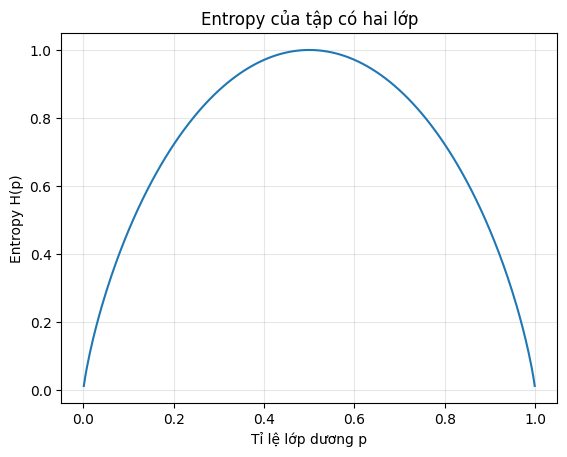

In [3]:
p = np.linspace(0.001, 0.999, 300)
H = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
plt.plot(p, H)
plt.xlabel('Tỉ lệ lớp dương p'); plt.ylabel('Entropy H(p)')
plt.title('Entropy của tập có hai lớp'); plt.grid(alpha=0.3)
plt.show()

## 2. Information Gain trên dữ liệu thời tiết

In [4]:
DATA = Path('..') / 'data'
df = pd.read_csv(DATA / 'weather.csv')
print('H(S) = %.3f' % entropy(df['play']))

H(S) = 1.000


Tính chi tiết cho thuộc tính `weather`: entropy từng tập con và entropy trung bình có trọng số.

In [5]:
weighted = 0
for value, subset in df.groupby('weather'):
    h = entropy(subset['play'])
    weighted += len(subset) / len(df) * h
    print('%-7s %d mẫu, Yes = %d, No = %d, H = %.3f' % (value, len(subset), (subset['play'] == 'Yes').sum(), (subset['play'] == 'No').sum(), h))
print('Entropy sau khi chia = %.3f' % weighted)
print('IG(S, weather) = %.3f' % (entropy(df['play']) - weighted))

Cloudy  3 mẫu, Yes = 3, No = 0, H = 0.000
Rainy   4 mẫu, Yes = 1, No = 3, H = 0.811
Sunny   3 mẫu, Yes = 1, No = 2, H = 0.918
Entropy sau khi chia = 0.600
IG(S, weather) = 0.400


So sánh IG của cả bốn thuộc tính. Thuộc tính có IG lớn nhất được chọn làm nút gốc.

In [6]:
attributes = ['weather', 'temperature', 'humidity', 'wind']
gains = {a: information_gain(df, a) for a in attributes}
for a, g in sorted(gains.items(), key=lambda item: -item[1]):
    print('IG(S, %-11s) = %.4f' % (a, g))

IG(S, weather    ) = 0.4000
IG(S, wind       ) = 0.1245
IG(S, temperature) = 0.1145
IG(S, humidity   ) = 0.0349


## 3. Tiếp tục chia các nhánh chưa tinh khiết

Nhánh `Cloudy` đã tinh khiết (3 Yes). Với nhánh `Sunny` và `Rainy`, tính lại IG trên tập con với các thuộc tính còn lại.

In [7]:
for value in ['Sunny', 'Rainy']:
    subset = df[df['weather'] == value]
    print('Nhánh weather = %s: %d mẫu, H = %.3f' % (value, len(subset), entropy(subset['play'])))
    for a in ['temperature', 'humidity', 'wind']:
        print('    IG(%s) = %.3f' % (a, information_gain(subset, a)))

Nhánh weather = Sunny: 3 mẫu, H = 0.918
    IG(temperature) = 0.918
    IG(humidity) = 0.918
    IG(wind) = 0.252
Nhánh weather = Rainy: 4 mẫu, H = 0.811
    IG(temperature) = 0.123
    IG(humidity) = 0.123
    IG(wind) = 0.811
